# Zilionis 2019 NSCLC — 03 · Signatures & Gate 2

**Gate 2** asks whether the embryonic module pattern appears. In the non-branching case that means a shared developmental gradient — here a monotone **Gast→pSom** axis — with **Crest** as an inverse/off-axis terminal readout. Geography is read from the graph-smoothed scores; the deliverable panels show the **raw** per-cell scores.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
ds   = name.split('-')[0] if '-' in name else name
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)


In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src, lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 3920 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 79/81 genes present
pSom: 95/98 genes present
Crest: 104/104 genes present


### Gate 2 — module geography and the developmental gradient
Read geography from smoothed scores; the gradient along pseudotime; and where the Crest-high cells sit. A shared Gast→pSom gradient with an off-axis Crest readout passes Gate 2 (non-branching). Gate 3 (branching-only cross-repression) is NA because there is no Gast/pSom co-expression hub.

In [4]:
print('smoothed spatial correlations (geography):')
for a, b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('\ngradient along pseudotime (Spearman rho on smoothed):')
for sn in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[sn]); print(f'  {sn}: rho = {rho:+.3f}')
for m in ['Gast','pSom','Crest']:
    v = adata.obs[m+'_sm'].values; hi = v >= np.quantile(v, 0.9)
    print(f'{m}-high decile mean pseudotime = {tn[hi].mean():.2f}')
print('\nglobal module means (raw):', {m: round(float(adata.obs[m].mean()),3) for m in ['Gast','pSom','Crest']})
print('\nGATE 2: shared Gast->pSom developmental gradient present; Crest an inverse off-axis readout -> GO (non-branching)')
print('GATE 3: no Gast/pSom co-expression hub / stable branch point -> NA')
print('CREST FLAG: Crest peaks mid-pseudotime (off-axis), not at the pSom terminus -> flagged, passes anyway')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.53
  Crest_sm vs Gast_sm: r = -0.51
  Crest_sm vs pSom_sm: r = -0.36

gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.587
  pSom_sm: rho = +0.762
  Crest_sm: rho = +0.019
Gast-high decile mean pseudotime = 0.14
pSom-high decile mean pseudotime = 0.99
Crest-high decile mean pseudotime = 0.56

global module means (raw): {'Gast': -0.009, 'pSom': 0.039, 'Crest': -0.022}

GATE 2: shared Gast->pSom developmental gradient present; Crest an inverse off-axis readout -> GO (non-branching)
GATE 3: no Gast/pSom co-expression hub / stable branch point -> NA
CREST FLAG: Crest peaks mid-pseudotime (off-axis), not at the pSom terminus -> flagged, passes anyway


### Module maps (raw per-cell scores, house linear layout)

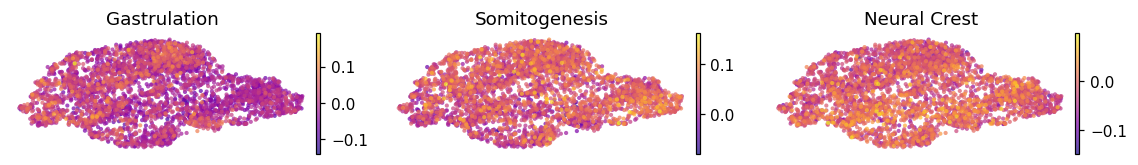

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, axes = plt.subplots(1, 3, figsize=(10.5,1.6))
for ax, (m, title) in zip(axes, modules.items()):
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=title)
    ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
fig.tight_layout(); plt.show()

### Deliverables — per-module signature PDFs + colorbars (raw scores)

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


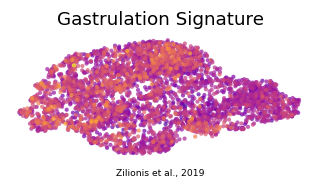

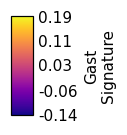

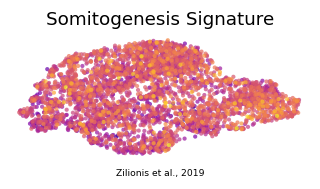

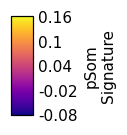

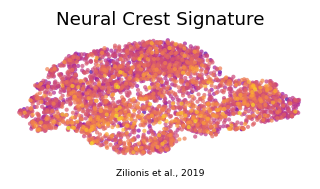

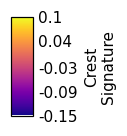

In [6]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
    ax.text(.5, -.12, 'Zilionis et al., 2019', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    plt.show(); print('saved', f'{m}_signature.pdf', '+ colorbar')

In [7]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (3920, 28282)
